 02 - Exploring Topics in Negative Reviews

  Goal --
Identify recurring issues customers mention in negative restaurant reviews and explore whether the themes vary across restaurant categories.

 Questions
- What topics appear most often in negative reviews? (could be anything entirely)
- Which topics are common across categories, and which seem more specific to certain categories? 


 Approach -- 
We’ll prepare the review text,find the reviews that are not in the category of restaurants tht have to do with them , explore recurring words or themes, and compare the results across categories where the data supports it.

In [ ]:
from getpass import getpass     # connected to database to get some example reviews
import pandas as pd
from sqlalchemy import create_engine, inspect, text
from sqlalchemy.engine import URL

password = getpass("PostgreSQL password: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="yelp_project",
))

columns = [column["name"] for column in inspect(engine).get_columns("reviews", schema="clean")]
print("Review table columns:", columns)

text_columns = [
    column for column in columns
    if column.lower() in {"text", "review_text", "review"}
]

if not text_columns:
    print("No obvious review-text column found. Check the column list above.")
else:
    text_column = text_columns[0]
    query = text(
        f'SELECT review_id, stars, star_group, "{text_column}" AS review_text '
        "FROM clean.reviews "
        "WHERE star_group = :group "
        "LIMIT 5"
    )
    examples = pd.read_sql_query(query, engine, params={"group": "negative"})
    print(examples[["review_id", "stars", "review_text"]].to_string(index=False))



    # checking my connection to the database...and an example query to get some data from the reviews table.

Review table columns: ['review_id', 'user_id', 'business_id', 'stars', 'star_group', 'review_datetime', 'review_date', 'review_year', 'review_month', 'is_partial_year', 'useful_votes', 'funny_votes', 'cool_votes', 'review_text', 'text_length', 'is_short_review', 'has_url']
             review_id  stars                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

In [ ]:
check_categories = text("""
    SELECT r.review_id, r.business_id, c.category
    FROM clean.reviews AS r
    JOIN clean.business_categories AS c USING (business_id)
    WHERE r.review_id = :review_id
    ORDER BY c.category
""")

pd.read_sql_query(
    check_categories,
    engine,
    params={"review_id": "-nQRvxUGWYUBqTZdcyvprQ"},  # selected this particular id
)

# checking the categories for a specific review to see if the join works correctly.
# this is just to find the reviews for restuarants only 

# ISSUE - some other categories might have restuarant reviews because the business has multiple categories. 
# For example, a business could be both a "restaurant" and a "bar", and the review might be about the bar aspect. 
# So we need to filter for reviews that are specifically about restaurants.


# SOLUTION - filter for reviews that are specifically about restaurants

# Purely restaurants by category : keep every review.
# Mixed businesses: keep a review only if its text is mostly about dining, 
# meaning it mentions food, the menu, servers, dishes and so on more than rooms, the cover charge, gas pumps and so on.

,review_id,business_id,category
0,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Event Planning & Services
1,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Hotels
2,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Hotels & Travel
3,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Restaurants
4,-nQRvxUGWYUBqTZdcyvprQ,I2Yt74AzSQFfyQqgN7PSEg,Venues & Event Spaces


In [ ]:
# load ALL reviews + mark businesses whose tags are mixed (not purely a restaurant)
import re  # like ctrl+f but it can match any words and their variations at once 

MIXED_TAGS = [
    "Nightlife", "Bars", "Hotels", "Hotels & Travel", "Casinos",
    "Venues & Event Spaces", "Event Planning & Services", "Arts & Entertainment",
    "Grocery", "Convenience Stores", "Gas Stations",
]

reviews = pd.read_sql_query(text("""
    SELECT r.review_id, r.business_id, r.stars, r.star_group, r.review_text,
           EXISTS (SELECT 1 FROM clean.business_categories c
                   WHERE c.business_id = r.business_id
                     AND c.category = ANY(:mixed_tags)) AS is_mixed_business
    FROM clean.reviews r
"""), engine, params={"mixed_tags": MIXED_TAGS})

print(f"{len(reviews):,} reviews | from mixed businesses: {reviews.is_mixed_business.mean():.1%}")

# shows the percentage of mixed reviews from the total number of reviews 


307,510 reviews | from mixed businesses: 35.9%


In [ ]:
# Word lists: words that show a review is about eating at the restaurant, and words that show it's about something else
# This is basically AI analysis - AI helped me generate this code to look for reviews that have to do with dining , restaurants and any others of the sort 


DINING_WORDS = r"""\b(?:food|dish(?:es)?|meals?|menu|order(?:ed)?|servers?|waiter|waitress|waitstaff|
    ate|eat(?:ing)?|tast(?:e|ed|y|eless)|flavou?r|bland|(?:under|over)?cooked|chef|kitchen|
    appetizers?|entrees?|desserts?|lunch|dinner|breakfast|brunch|burgers?|pizza|sandwich(?:es)?|
    salads?|steak|chicken|fries|sushi|tacos?|wings|soup|sauce|portions?|plates?|restaurant|
    reservation|delicious|soggy|greasy|buffet|takeout|delivery|seafood|fish|bread|rice)\b"""

NON_DINING_WORDS = r"""\b(?:(?<!dining )rooms?|beds?|front desk|check[- ]?in|check[- ]?out|housekeeping|
    lobby|pool|casino|slots?|concert|tickets?|stage|cover charge|bouncers?|dj|dance floor|
    gas|pumps?|aisles?|groceries)\b"""

dining_re = re.compile(DINING_WORDS, re.IGNORECASE | re.VERBOSE)
non_dining_re = re.compile(NON_DINING_WORDS, re.IGNORECASE | re.VERBOSE)

# Count how many times each kind of word appears in every review
reviews["dining_hits"] = reviews.review_text.str.count(dining_re)
reviews["non_dining_hits"] = reviews.review_text.str.count(non_dining_re)

reviews[["review_text", "dining_hits", "non_dining_hits"]].head()   # checking those 5 rows to see how many dining words were in the review sentence 


,review_text,dining_hits,non_dining_hits
0,Family diner. Had the buffet. Eclectic assortm...,5,0
1,Good food--loved the gnocchi with marinara\nth...,3,0
2,Tremendous service (Big shout out to Douglas) ...,2,0
3,Best thai food in the area. Everything was au...,2,0
4,My go to menu is coconut soup and pad thai wit...,8,0


In [6]:
# A review is "about dining" if it has at least 1 dining word AND at least as many dining words as non-dining words
about_dining = (reviews.dining_hits >= 1) & (reviews.dining_hits >= reviews.non_dining_hits)

# Pure restaurant -> always keep (its tags already tell the truth)
# Mixed business  -> keep only if the text is about dining
reviews["is_restaurant_review"] = (~reviews.is_mixed_business) | about_dining

mixed = reviews[reviews.is_mixed_business]
print(f"Mixed-business reviews kept: {mixed.is_restaurant_review.sum():,} of {len(mixed):,} ({mixed.is_restaurant_review.mean():.1%})")
print(f"All reviews kept:            {reviews.is_restaurant_review.sum():,} of {len(reviews):,}")


Mixed-business reviews kept: 99,284 of 110,286 (90.0%)
All reviews kept:            296,508 of 307,510


In [7]:
# Read 10 reviews it kept and 10 it dropped, all from mixed businesses
pd.set_option("display.max_colwidth", 300)
for label, keep in [("KEPT", True), ("DROPPED", False)]:
    print(f"\n===== {label} =====")
    sample = mixed[mixed.is_restaurant_review == keep].sample(10, random_state=42)
    print(sample[["stars", "dining_hits", "non_dining_hits", "review_text"]].to_string(index=False))



===== KEPT =====
 stars  dining_hits  non_dining_hits                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

THIS IS THE NEGATIVE REVIEW ASPECT WHERE YOU CAN SEE WHAT TOPICS CAUSE THE MOST NEGATIVE REVIEWS 

(1) Define complaint topics, each with a list of words people use when they complain about it (the same word-spotter idea as before).

(2) Tag every restaurant review with the topics it mentions. One review can mention several.

(3) Count how often each topic shows up in negative reviews. That's what people complain about most.

(4) Compare with positive reviews. A word like "price" turns up in happy reviews too, so a topic only counts as a real complaint if it's much more common in negative reviews.



In [9]:
# Final datasets: keep only the reviews that are about restaurants (pure restaurants + dining reviews from mixed businesses)
restaurant_reviews = reviews[reviews.is_restaurant_review].copy()
print(f"Restaurant reviews kept for the topic analysis: {len(restaurant_reviews):,}")

Restaurant reviews kept for the topic analysis: 296,508


In [10]:
# Each topic = words people typically use when complaining about it
TOPICS = {
    "Food quality":     r"\b(?:cold|bland|tasteless|flavou?rless|undercooked|overcooked|raw|stale|burnt|burned|soggy|greasy|salty|dry|inedible|frozen|microwaved|gross|disgusting|nasty)\b",
    "Rude service":     r"\b(?:rude|attitude|ignored|unprofessional|unfriendly|disrespectful|condescending|yelled|unhelpful|didn'?t care|manager)\b",
    "Long wait":        r"\b(?:wait(?:ed|ing)?|slow|forever|took (?:so |too )?long|\d+\s*(?:minutes|mins|hours?)|an hour)\b",
    "Wrong order":      r"\b(?:wrong (?:order|item|food|dish)|got the wrong|missing|forgot|forgotten|never (?:came|arrived)|mixed up|incorrect|left out)\b",
    "Price / value":    r"\b(?:overpriced|expensive|pricey|prices?|priced|overcharged|charged?|bill|money|not worth|rip[- ]?off|refund)\b",
    "Cleanliness":      r"\b(?:dirty|filthy|sticky|unsanitary|hair|flies|bugs?|roach(?:es)?|cockroach(?:es)?|mou?ld(?:y)?|smell(?:s|ed|y)?|stinks?)\b",
    "Got sick":         r"\b(?:sick|food poisoning|vomit(?:ed|ing)?|diarrh(?:ea|oea)|threw up|throwing up|stomach)\b",
    "Atmosphere":       r"\b(?:loud|noisy|music|crowded|cramped|decor|ambian(?:c|s)e|atmosphere)\b",
}

# Tag every restaurant review: True if it mentions the topic at least once
for topic, pattern in TOPICS.items():
    restaurant_reviews[topic] = restaurant_reviews.review_text.str.contains(
        re.compile(pattern, re.IGNORECASE)
    )

topic_names = list(TOPICS)
negative_reviews = restaurant_reviews[restaurant_reviews.star_group == "negative"]
positive_reviews = restaurant_reviews[restaurant_reviews.star_group == "positive"]
print(f"Negative: {len(negative_reviews):,} | Positive: {len(positive_reviews):,}")


Negative: 60,586 | Positive: 201,839


In [14]:
# What do negative reviews complain about most?
# .mean() on a True/False column = share of reviews that mention the topic
topic_summary = pd.DataFrame({
    "share_of_negative": negative_reviews[topic_names].mean(),
    "share_of_positive": positive_reviews[topic_names].mean(),
})
# How many times more common the topic is in negative reviews than in positive ones
# 1x = people mention it just as much when happy (weak complaint signal), 5x = clearly a complaint
topic_summary["times_more_in_negative"] = topic_summary.share_of_negative / topic_summary.share_of_positive
topic_summary = topic_summary.sort_values("share_of_negative", ascending=False)

untagged = (~negative_reviews[topic_names].any(axis=1)).mean()
print(f"Negative reviews matching NO topic: {untagged:.1%}")
print("Note: one review can mention several topics, so the shares add up to more than 100%.")

# Show the table with readable % values (no extra library needed)
display_table = topic_summary.copy()
display_table["share_of_negative"] = display_table.share_of_negative.map("{:.1%}".format)
display_table["share_of_positive"] = display_table.share_of_positive.map("{:.1%}".format)
display_table["times_more_in_negative"] = display_table.times_more_in_negative.map("{:.1f}x".format)
display_table


Negative reviews matching NO topic: 18.7%
Note: one review can mention several topics, so the shares add up to more than 100%.


,share_of_negative,share_of_positive,times_more_in_negative
Food quality,35.0%,8.1%,4.3x
Long wait,34.8%,15.5%,2.2x
Price / value,29.8%,16.6%,1.8x
Rude service,20.0%,2.4%,8.4x
Atmosphere,9.2%,17.2%,0.5x
Cleanliness,8.7%,1.9%,4.5x
Wrong order,7.1%,1.6%,4.6x
Got sick,3.2%,0.5%,6.2x


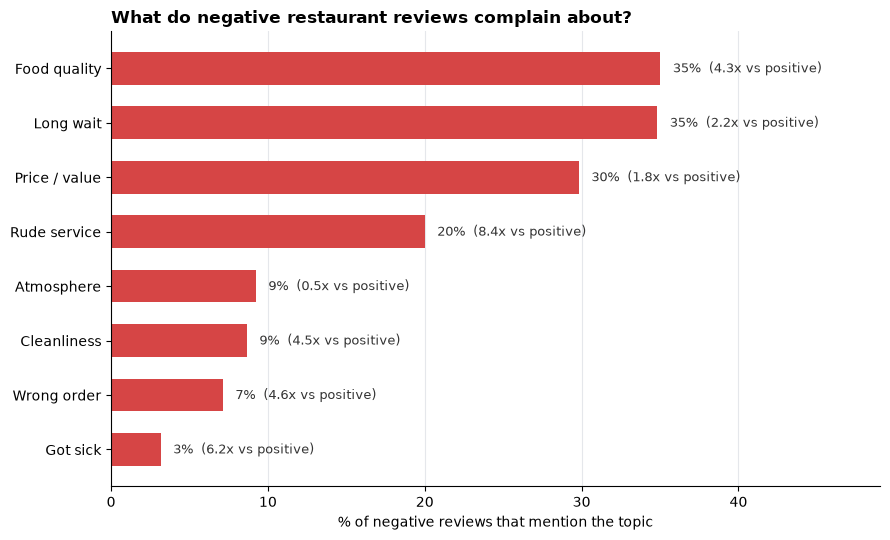

In [15]:
# Chart: share of negative reviews that mention each topic (biggest at the top)
import matplotlib.pyplot as plt

plot_data = topic_summary.sort_values("share_of_negative")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_data.index, plot_data.share_of_negative * 100, color="#D64545", height=0.6)

# Label each bar with its % and how much more common it is in negative than positive reviews
for y, (share, lift) in enumerate(zip(plot_data.share_of_negative, plot_data.times_more_in_negative)):
    ax.text(share * 100 + 0.8, y, f"{share:.0%}  ({lift:.1f}x vs positive)",
            va="center", fontsize=9, color="#333333")

ax.set_xlabel("% of negative reviews that mention the topic")
ax.set_title("What do negative restaurant reviews complain about?", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, plot_data.share_of_negative.max() * 100 * 1.4)
plt.tight_layout()
plt.show()

In [16]:
# Sanity check: read 3 real negative reviews per topic to confirm the tags make sense
pd.set_option("display.max_colwidth", 250)
for topic in topic_names:
    print(f"\n===== {topic} =====")
    print(negative_reviews.loc[negative_reviews[topic], "review_text"].sample(3, random_state=1).to_string(index=False))


===== Food quality =====
Ok...I've been on a best burger in St. Louis quest for awhile..I read the reviews on here so decided to check it out. First off waited 45 minutes for a table for five of us. Dont mind the wait if its worth it.  The place is loud.  Couldn't hear ea...
Because this place came so highly recommended, we had decided that we needed to stop at Brophy Brothers on our way up to wine country. My friends and I (3 couples total) arrived expecting to wait for a table; we were not surprised when we were tol...
Just got back from dinner there.  Had the all you can eat sushi with my wife...enjoyed 3 rolls, tried a "Spicy Salmon" roll and it was gross...tasted like fish was maybe rancid.  Waiter told us since we didn't finish it we would be charged an addi...

===== Rude service =====
We are trying to do our best to support our local friends in the industry. We ordered XL pizza, Ravs, Sandwich and one of the new french bread pizzas. Usually we pick up, but I had messed with ch

### How to read the results
- **Share of negative reviews** = what people complain about most.
- **Times more in negative** = how strongly the topic signals a complaint. Near 1x means people mention it just as often in happy reviews (e.g. "great prices!"), so treat it as a weaker complaint signal.
- **Caution:** topics are found with keyword lists, so they are approximate. A review can mention several topics, and reviews that match no topic are not counted. The planned AI tagging step will refine this.